# 06 — Explainability
Which graduate characteristics are associated with being unemployed
(RQ4)?

Two complementary views, both computed so that their uncertainty is
visible:

1. **Logistic-regression odds ratios.** Logistic regression is the most
   accurate and most stable model in this study (`07_robustness.ipynb`),
   and its coefficients are directly interpretable. Odds ratios are for
   *unemployment*, per one standard deviation of a numeric feature, with
   a bootstrap CI over respondents.
2. **Cross-validated permutation importance** for logistic regression
   and, for comparison, the class-weighted Random Forest (A1): the drop
   in held-out PR-AUC when a feature is shuffled, measured on each of the
   50 CV test folds (5-fold x 10 repeats, all 157 rows), with a corrected
   CI across folds.

These are **associations in one cross-sectional survey, not causal
effects**: e.g. a feature can matter because it marks a cohort or
program with different survey timing or labour-market conditions.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.feature_engineering import CANDIDATE_FEATURES, NUMERIC_FEATURES, NOMINAL_FEATURES, TARGET_COLUMN
from src.classification_models import build_baseline_models, build_a1_random_forest
from src.explainability import cv_permutation_importance, logreg_odds_ratios
from src.reporting import save_figure, save_table

warnings.filterwarnings("ignore", category=UserWarning)

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "tracer_study_processed.csv")
X, y = df[CANDIDATE_FEATURES], df[TARGET_COLUMN].astype(int)
print(X.shape, f"unemployed: {(y == 0).sum()}")

(157, 10) unemployed: 31


## 1. Logistic-regression odds ratios (unemployment)

,feature,odds_ratio_unemployed,ci_low,ci_high,share_boot_or_above_1
0,nominal__program_BSEd Math,2.101,0.945,5.059,0.963
1,numeric__sex,1.314,0.823,2.453,0.884
2,numeric__learning_experience_index,1.297,0.758,2.793,0.857
3,numeric__guidance_support_index,1.109,0.540,2.209,0.616
4,numeric__school_choice_index,1.098,0.577,1.844,0.635
5,numeric__age,1.015,0.514,1.557,0.535
6,nominal__program_BEED,0.815,0.374,1.666,0.270
7,nominal__program_BSEd English,0.788,0.411,1.668,0.289
8,nominal__program_BSEd Science,0.734,0.246,1.640,0.238
9,numeric__study_hours,0.719,0.348,1.213,0.087


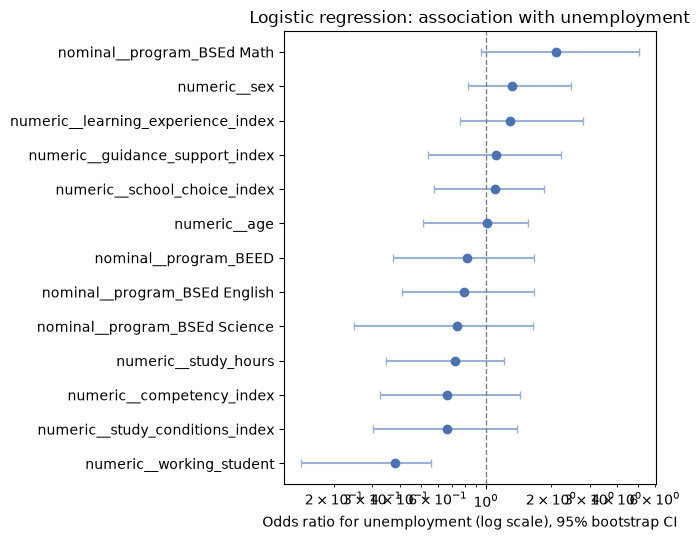

In [2]:
logreg = build_baseline_models(NUMERIC_FEATURES, NOMINAL_FEATURES)["BL2_LogReg_Balanced"]
odds = logreg_odds_ratios(logreg, X, y, n_boot=1000)
display(odds.round(3))
save_table(odds, "logreg_odds_ratios", index=False)

fig, ax = plt.subplots(figsize=(7, 5.5))
ordered = odds.iloc[::-1]
ax.errorbar(ordered["odds_ratio_unemployed"], range(len(ordered)),
            xerr=[ordered["odds_ratio_unemployed"] - ordered["ci_low"],
                  ordered["ci_high"] - ordered["odds_ratio_unemployed"]],
            fmt="o", color="#4c72b0", ecolor="#9ab0d6", capsize=3)
ax.axvline(1, linestyle="--", color="gray", linewidth=1)
ax.set_yticks(range(len(ordered)))
ax.set_yticklabels(ordered["feature"])
ax.set_xscale("log")
ax.set_xlabel("Odds ratio for unemployment (log scale), 95% bootstrap CI")
ax.set_title("Logistic regression: association with unemployment")
plt.tight_layout()
save_figure(fig, "logreg_odds_ratios")
plt.show()

**Reading this:** an odds ratio above 1 means higher values (or
membership in that program) go with *higher* odds of unemployment; below
1, lower odds. Numeric features are standardized, so their ratios are per
one standard deviation. A CI that crosses 1 means the direction isn't
established. Coefficients are L2-regularized (shrunk toward 1), and
program ratios are relative to the average program, not to one reference
program.

## 2. Cross-validated permutation importance

Logistic regression


,feature,importance_mean,ci_low,ci_high,share_folds_positive
0,working_student,0.0786,0.0040,0.1532,0.86
1,study_hours,0.0183,-0.0325,0.0691,0.70
2,study_conditions_index,0.0172,-0.0369,0.0713,0.54
3,competency_index,0.0128,-0.0555,0.0812,0.52
4,program,0.0098,-0.0523,0.0718,0.52
5,guidance_support_index,-0.0018,-0.0304,0.0268,0.40
6,sex,-0.0036,-0.0360,0.0287,0.60
7,learning_experience_index,-0.0061,-0.0534,0.0413,0.54
8,age,-0.0103,-0.0374,0.0168,0.24
9,school_choice_index,-0.0161,-0.0609,0.0287,0.40


A1 Random Forest


,feature,importance_mean,ci_low,ci_high,share_folds_positive
0,working_student,0.0574,0.0072,0.1075,0.96
1,school_choice_index,0.0246,-0.0305,0.0797,0.62
2,study_hours,0.0227,-0.0296,0.0750,0.68
3,learning_experience_index,0.0083,-0.0413,0.0579,0.58
4,sex,0.0049,-0.0213,0.0311,0.62
5,study_conditions_index,0.0009,-0.0586,0.0605,0.52
6,competency_index,-0.0098,-0.0661,0.0466,0.38
7,guidance_support_index,-0.0113,-0.0524,0.0299,0.40
8,age,-0.0149,-0.0549,0.0251,0.36
9,program,-0.0238,-0.0894,0.0418,0.32


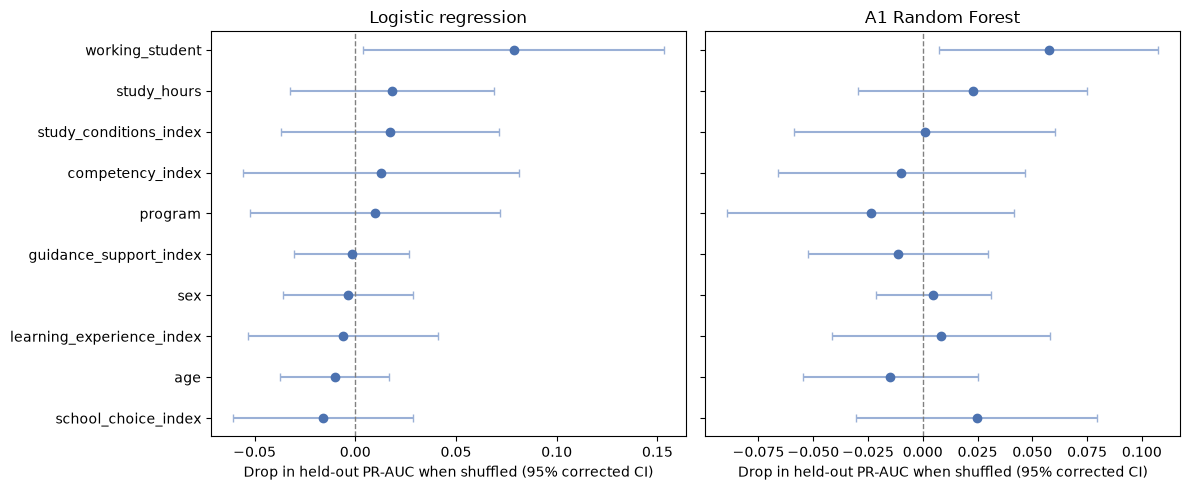

In [3]:
importance = {}
for name, model in {
    "Logistic regression": logreg,
    "A1 Random Forest": build_a1_random_forest(NUMERIC_FEATURES, NOMINAL_FEATURES),
}.items():
    summary, per_fold = cv_permutation_importance(model, X, y, perm_repeats=10)
    importance[name] = summary
    print(name); display(summary.round(4))

save_table(importance["Logistic regression"], "cv_permutation_importance_logreg", index=False)
save_table(importance["A1 Random Forest"], "cv_permutation_importance_rf", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
order = importance["Logistic regression"]["feature"].tolist()[::-1]
for ax, (name, summary) in zip(axes, importance.items()):
    s = summary.set_index("feature").loc[order]
    ax.errorbar(s["importance_mean"], range(len(s)),
                xerr=[s["importance_mean"] - s["ci_low"], s["ci_high"] - s["importance_mean"]],
                fmt="o", color="#4c72b0", ecolor="#9ab0d6", capsize=3)
    ax.axvline(0, linestyle="--", color="gray", linewidth=1)
    ax.set_yticks(range(len(s)))
    ax.set_yticklabels(s.index)
    ax.set_title(name)
    ax.set_xlabel("Drop in held-out PR-AUC when shuffled (95% corrected CI)")
plt.tight_layout()
save_figure(fig, "cv_permutation_importance")
plt.show()

**Reading this:** each point is the average drop in PR-AUC on held-out
folds when that feature is shuffled; a CI that includes 0 means the model
doesn't reliably depend on that feature for out-of-sample performance.
`share_folds_positive` in the tables shows how consistently the feature
helps across the 50 folds.